# Automated Harmful Algal Bloom (HAB) Detection via Satellite Remote Sensing

**Author:** Vasanth (`vasanth-09ux`)  
**Academic Programme:** Integrated M.Tech in Software Engineering, VIT Chennai  
**Sensors & Platform:** Copernicus Sentinel-2 (Level-2A Surface Reflectance), Google Earth Engine (GEE), Python  

---

## Abstract & Problem Overview
Harmful Algal Blooms (HABs) pose severe threats to aquatic ecosystems, marine life, and coastal drinking water reserves by depleting dissolved oxygen (hypoxia) and producing toxic compounds. Traditional marine sampling is geographically constrained and labor-intensive. Satellite remote sensing enables macro-scale, high-frequency surveillance.

This project implements an end-to-end unsupervised analytical pipeline that:
1. Interfaces with **Google Earth Engine (GEE)** to retrieve cloud-filtered Sentinel-2 Level-2A imagery (`COPERNICUS/S2_SR_HARMONIZED`).
2. Downloads high-resolution surface reflectance bands: **B2 (Blue)**, **B3 (Green)**, **B4 (Red)**, **B8 (NIR)**, and **B11 (SWIR-1)**.
3. Computes the **Normalized Difference Water Index (NDWI)** to delineate surface water bodies and isolates them via mathematical morphology.
4. Extracts spectral indices across water pixels: **Normalized Difference Vegetation Index (NDVI)** and the **Floating Algae Index (FAI)**.
5. Applies **K-Means clustering ($k=4$)** over the multi-spectral feature space and computes a composite bloom likelihood score to classify potential bloom zones.
6. Renders a comprehensive 6-panel spatial diagnostic visualization.

## 1. Environment & Dependency Setup
The pipeline utilizes `earthengine-api` and `geemap` for satellite ingestion, `rasterio` for GeoTIFF manipulation, and `scikit-learn` for unsupervised clustering.

In [1]:
# Install dependencies if running in Colab or a fresh virtual environment
# !pip install earthengine-api geemap rasterio scikit-learn matplotlib scipy numpy requests

import os
import math
from datetime import datetime
import requests
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import ndimage
from sklearn.cluster import KMeans
import ee
import geemap

print("Environment initialized successfully.")

## 2. Google Earth Engine (GEE) Authentication
Google Earth Engine requires authentication linked to a Google Cloud project with the Earth Engine API enabled.

> **Note:** Set your GCP project ID below or configure the `GEE_PROJECT_ID` environment variable.

In [2]:
# Specify Google Cloud Project ID with GEE enabled
PROJECT_ID = os.environ.get("GEE_PROJECT_ID", "your-gee-project-id")

try:
    ee.Initialize(project=PROJECT_ID)
    print(f"GEE initialized successfully with project: {PROJECT_ID}")
except Exception as e:
    print(f"Initialization prompt: Authenticating GEE...")
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)

## 3. AOI Definition & Satellite Image Filtering
We filter the Sentinel-2 Harmonized Top-of-Atmosphere/Surface-Reflectance collection (`COPERNICUS/S2_SR_HARMONIZED`) over the Bay of Bengal / coastal Andhra Pradesh region (center: `[17.7009, 83.277]`, bbox: `[80, 15, 86, 20]`) with a cloud filter of $< 20\%$ coverage.

In [3]:
START_DATE = '2022-01-01'
END_DATE = '2022-01-31'
CLOUD_FILTER = ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)

def get_sentinel_layer(region, start_date=START_DATE, end_date=END_DATE):
    """Filters Sentinel-2 collection and returns mean surface reflectance."""
    s2_collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterDate(start_date, end_date)
        .filterBounds(region)
        .filter(CLOUD_FILTER)
    )
    return s2_collection.mean()

# Default bounding box [min_lon, min_lat, max_lon, max_lat]
default_region = ee.Geometry.BBox(80, 15, 86, 20)
sentinel_image = get_sentinel_layer(default_region)

# Interactive Map
Map = geemap.Map(center=[17.7009, 83.277], zoom=8)
visualization = {'min': 0, 'max': 3000, 'bands': ['B4', 'B3', 'B2']}
Map.addLayer(sentinel_image.select(['B4', 'B3', 'B2']), visualization, "Sentinel-2 True Color View")
Map.add_draw_control()
Map.add_layer_control()
Map

## 4. Multi-Spectral Band Retrieval & Tiling Engine
Sentinel-2 bands are downloaded via GEE direct URLs. When the designated Region of Interest (ROI) exceeds safe single-payload limits ($2.5 \times 10^7$ pixels), a spatial subdivision tiler partitions the bounding box into manageable sub-tiles.

In [4]:
def download_band(image, band_name, region, output_dir, scale=100):
    """Downloads an individual band GeoTIFF with size verification."""
    os.makedirs(output_dir, exist_ok=True)
    band_image = image.select(band_name)
    
    url = band_image.getDownloadURL({
        'scale': scale,
        'region': region,
        'format': 'GEO_TIFF',
        'crs': 'EPSG:4326',
        'filePerBand': True
    })
    
    response = requests.get(url, stream=True)
    if response.status_code == 200:
        out_file = os.path.join(output_dir, f'sentinel2_{band_name}.tif')
        with open(out_file, 'wb') as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)
        print(f"Successfully downloaded {band_name} -> {out_file}")
        return True
    else:
        print(f"Failed to download {band_name}. Status: {response.status_code}")
        return False

def download_sentinel_bands(output_dir='sentinel2_bands', scale=100, custom_roi=None):
    """Downloads required spectral bands (B2, B3, B4, B8, B11, B12)."""
    roi = custom_roi or (getattr(Map, 'user_roi', None) if 'Map' in globals() else None) or default_region
    image = get_sentinel_layer(roi)
    bands = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
    downloaded = []
    for b in bands:
        if download_band(image, b, roi, output_dir, scale=scale):
            downloaded.append(b)
    return downloaded

# To execute download when connected to GEE:
# download_sentinel_bands(output_dir='sentinel2_bands', scale=100)

## 5. Spectral Indices, Water Delineation & Unsupervised Bloom Detection

### Mathematical Formulations
1. **Normalized Difference Water Index (NDWI):**
   $$\text{NDWI} = \frac{\rho_{\text{Green}} - \rho_{\text{NIR}}}{\rho_{\text{Green}} + \rho_{\text{NIR}}} = \frac{B3 - B8}{B3 + B8}$$
   Pixels with $\text{NDWI} > 0.2$ are classified as water, followed by binary opening and closing (3×3 kernel) to eliminate noise.

2. **Normalized Difference Vegetation Index (NDVI):**
   $$\text{NDVI} = \frac{\rho_{\text{NIR}} - \rho_{\text{Red}}}{\rho_{\text{NIR}} + \rho_{\text{Red}}} = \frac{B8 - B4}{B8 + B4}$$

3. **Floating Algae Index (FAI):**
   $$\lambda_{\text{Red}} = 665\text{ nm}, \quad \lambda_{\text{NIR}} = 842\text{ nm}, \quad \lambda_{\text{SWIR}} = 1610\text{ nm}$$
   $$\rho_{\text{baseline}} = \rho_{\text{Red}} + (\rho_{\text{SWIR}} - \rho_{\text{Red}}) \times \left(\frac{842 - 665}{1610 - 665}\right)$$
   $$\text{FAI} = \rho_{\text{NIR}} - \rho_{\text{baseline}}$$

4. **K-Means Clustering & Scoring:**
   For all water pixels, features $[\rho_{\text{Blue}}, \rho_{\text{Green}}, \rho_{\text{Red}}, \rho_{\text{NIR}}, \text{NDVI}, \text{FAI}]$ are clustered into $k=4$ partitions. The bloom likelihood score for cluster $k$ is computed as:
   $$\text{Score}_k = 1.5 \cdot \bar{x}_{\text{NIR}} + 1.0 \cdot \left(\frac{\bar{x}_{\text{Green}}}{\bar{x}_{\text{Blue}} + 10^{-6}}\right) + 2.0 \cdot \bar{x}_{\text{FAI}}$$
   The cluster maximizing this score represents the highest probability algal bloom.


FAI Statistics:
Min FAI: -0.0598
Max FAI: 0.4522
Mean FAI: 0.0245

Cluster Analysis:

Cluster 0:
NIR value: 0.0308
Green/Blue ratio: 1.0930
FAI value: -0.0163
Bloom score: 1.1066

Cluster 1:
NIR value: 0.0359
Green/Blue ratio: 1.1720
FAI value: -0.0278
Bloom score: 1.1702

Cluster 2:
NIR value: 0.0917
Green/Blue ratio: 1.0598
FAI value: -0.0225
Bloom score: 1.1525

Cluster 3:
NIR value: 0.0304
Green/Blue ratio: 0.9763
FAI value: -0.0095
Bloom score: 1.0030


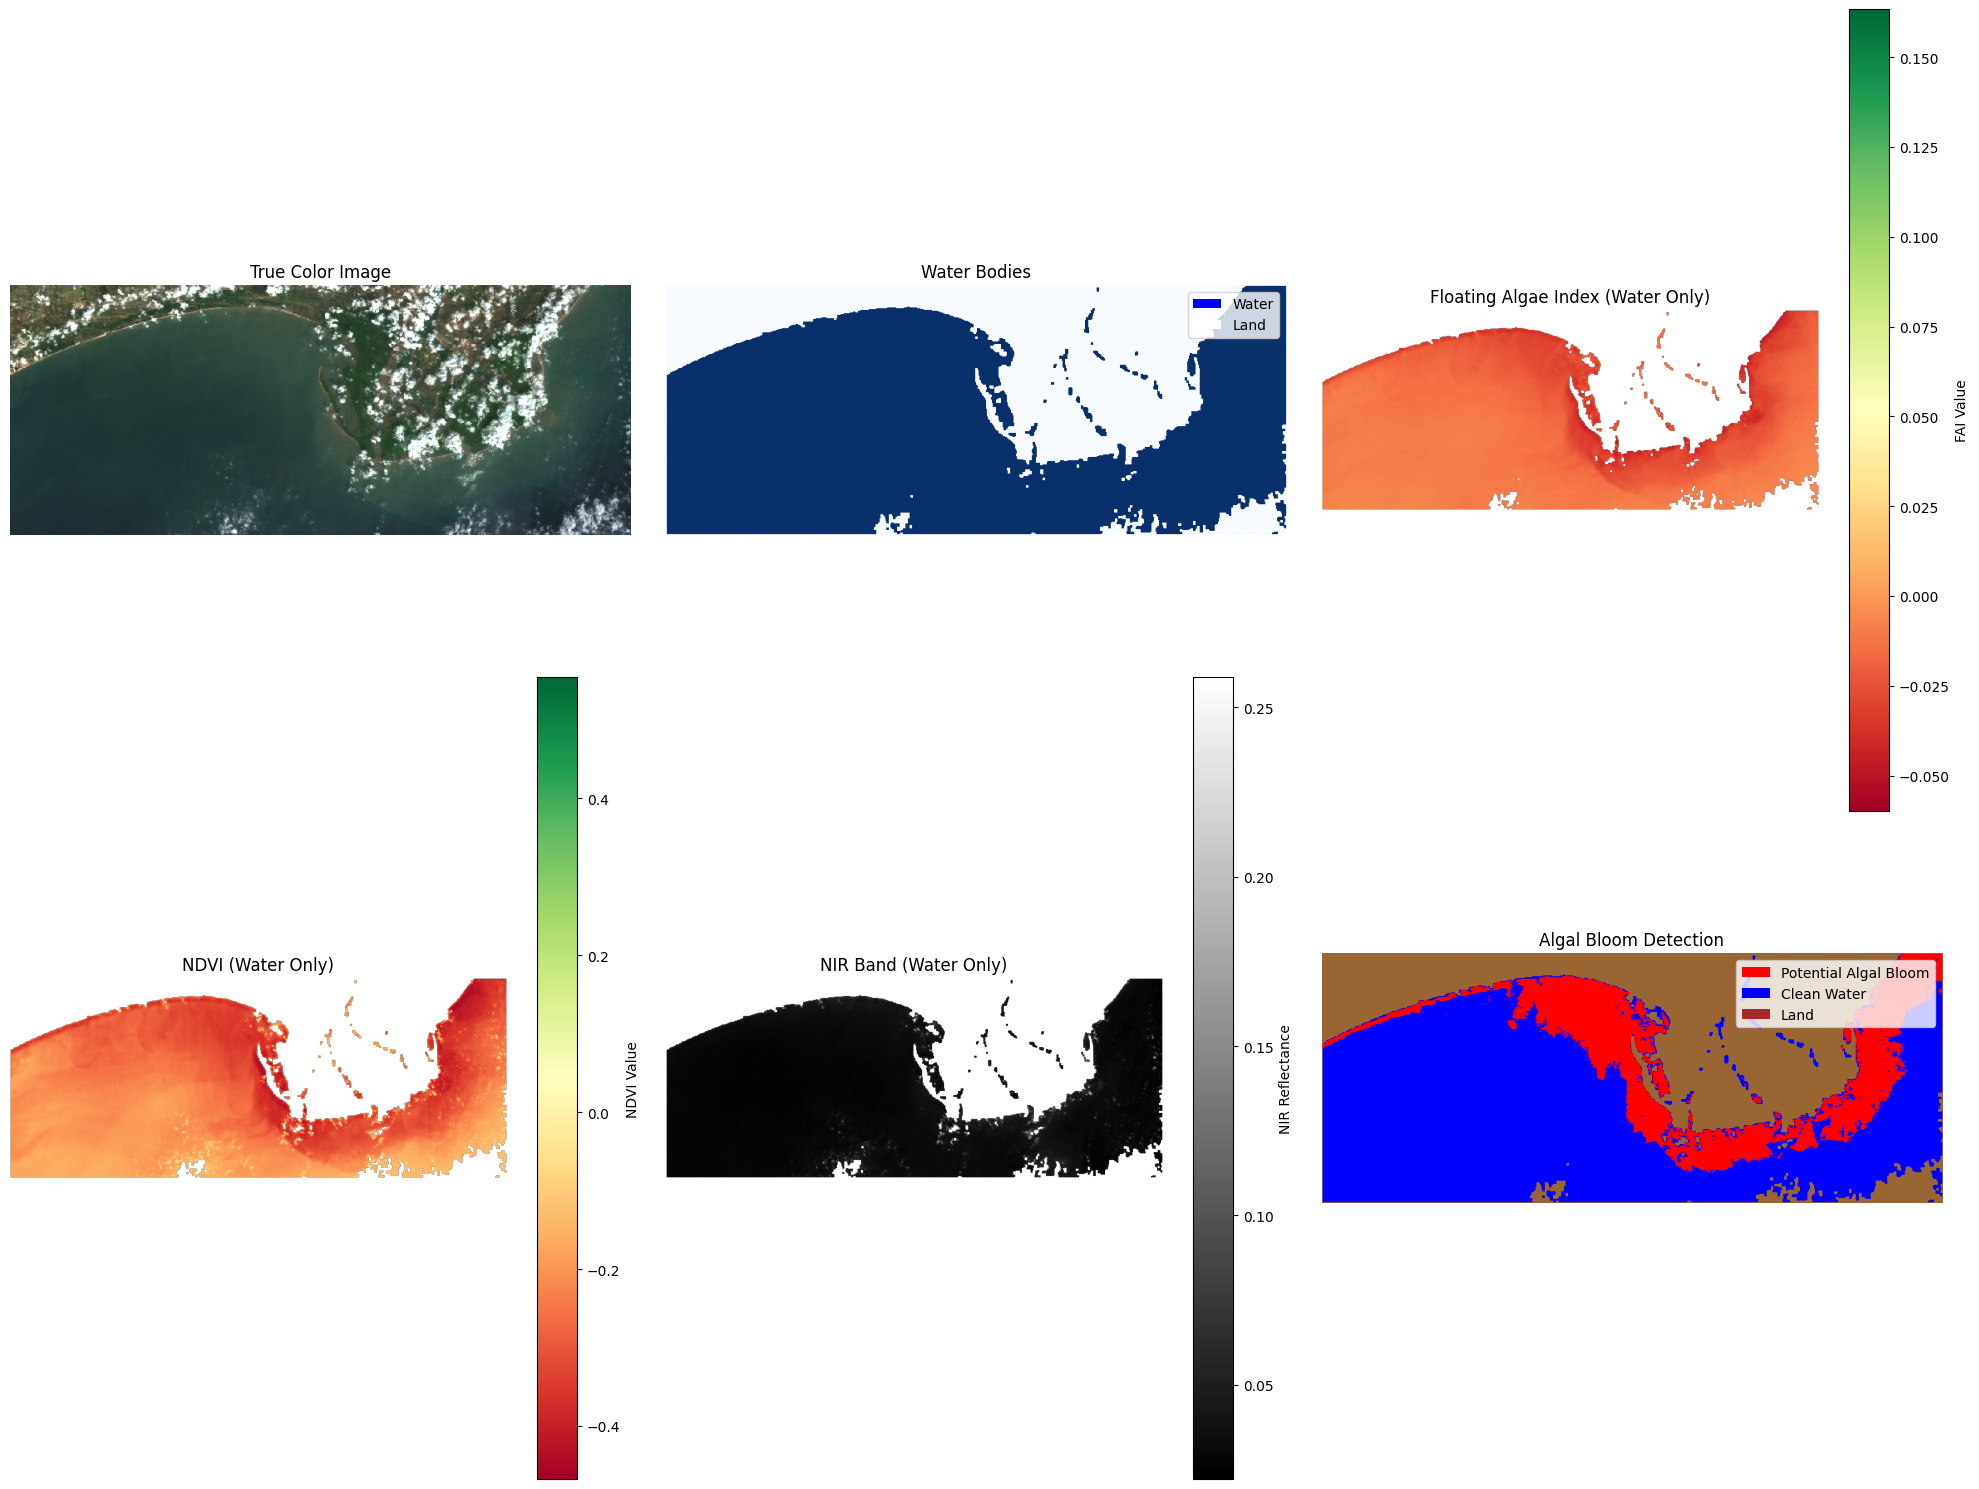

In [5]:
def detect_algal_blooms(input_dir='sentinel2_bands', save_plot_path=None):
    """
    Detects algal blooms in water bodies using Sentinel-2 imagery.
    """
    band_files = {
        'blue': os.path.join(input_dir, 'sentinel2_B2.tif'),
        'green': os.path.join(input_dir, 'sentinel2_B3.tif'),
        'red': os.path.join(input_dir, 'sentinel2_B4.tif'),
        'nir': os.path.join(input_dir, 'sentinel2_B8.tif'),
        'swir': os.path.join(input_dir, 'sentinel2_B11.tif')
    }

    WAVELENGTHS = {'red': 665, 'nir': 842, 'swir': 1610}

    bands_data = {}
    for band_name, file_path in band_files.items():
        with rasterio.open(file_path) as src:
            bands_data[band_name] = src.read(1).astype(float) / 10000.0

    # 1. Water Masking via NDWI
    ndwi = (bands_data['green'] - bands_data['nir']) / (bands_data['green'] + bands_data['nir'] + 1e-8)
    water_mask = ndwi > 0.2
    water_mask = ndimage.binary_opening(water_mask, structure=np.ones((3,3)))
    water_mask = ndimage.binary_closing(water_mask, structure=np.ones((3,3)))

    # 2. Vegetation & Algae Indices
    ndvi = (bands_data['nir'] - bands_data['red']) / (bands_data['nir'] + bands_data['red'] + 1e-8)
    ratio = (WAVELENGTHS['nir'] - WAVELENGTHS['red']) / (WAVELENGTHS['swir'] - WAVELENGTHS['red'])
    baseline_nir = bands_data['red'] + (bands_data['swir'] - bands_data['red']) * ratio
    fai = bands_data['nir'] - baseline_nir

    print(f"\nFAI Statistics:\nMin FAI: {np.nanmin(fai):.4f}\nMax FAI: {np.nanmax(fai):.4f}\nMean FAI: {np.nanmean(fai):.4f}")

    # 3. K-Means Multi-Spectral Clustering
    features = np.stack([
        bands_data['blue'], bands_data['green'], bands_data['red'],
        bands_data['nir'], ndvi, fai
    ], axis=-1)
    
    water_pixels = features[water_mask]
    if water_pixels.size > 0:
        n_clusters = 4
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        water_labels = kmeans.fit_predict(water_pixels)
        cluster_means = kmeans.cluster_centers_

        nir_idx, green_idx, blue_idx, fai_idx = 3, 1, 0, 5
        bloom_scores = (
            cluster_means[:, nir_idx] * 1.5 +
            (cluster_means[:, green_idx] / (cluster_means[:, blue_idx] + 1e-6)) * 1.0 +
            cluster_means[:, fai_idx] * 2.0
        )
        bloom_cluster = np.argmax(bloom_scores)
        bloom_mask = np.zeros_like(water_mask, dtype=bool)
        bloom_mask[water_mask] = (water_labels == bloom_cluster)

        print("\nCluster Analysis:")
        for i in range(n_clusters):
            print(f"\nCluster {i}:")
            print(f"NIR value: {cluster_means[i, nir_idx]:.4f}")
            print(f"Green/Blue ratio: {cluster_means[i, green_idx] / (cluster_means[i, blue_idx] + 1e-6):.4f}")
            print(f"FAI value: {cluster_means[i, fai_idx]:.4f}")
            print(f"Bloom score: {bloom_scores[i]:.4f}")
    else:
        bloom_mask = np.zeros_like(water_mask, dtype=bool)

    # 4. Comprehensive 6-Panel Visualization
    fig = plt.figure(figsize=(20, 15))
    true_color = np.stack([bands_data['red'], bands_data['green'], bands_data['blue']], axis=-1)
    top = np.percentile(true_color, 98)
    enhanced_tc = np.clip(true_color / (top + 1e-8), 0, 1)

    # P1: True Color
    ax1 = plt.subplot(231)
    plt.imshow(enhanced_tc)
    plt.title('True Color Image (B4-B3-B2)')
    plt.axis('off')

    # P2: Water Mask
    ax2 = plt.subplot(232)
    plt.imshow(water_mask, cmap='Blues')
    plt.title('Water Bodies (NDWI > 0.2)')
    ax2.legend(handles=[Patch(facecolor='blue', label='Water'), Patch(facecolor='white', label='Land')], loc='upper right')
    plt.axis('off')

    # P3: FAI
    ax3 = plt.subplot(233)
    plt.imshow(np.ma.masked_array(fai, ~water_mask), cmap='RdYlGn')
    plt.colorbar(label='FAI Value')
    plt.title('Floating Algae Index (Water Only)')
    plt.axis('off')

    # P4: NDVI
    ax4 = plt.subplot(234)
    plt.imshow(np.ma.masked_array(ndvi, ~water_mask), cmap='RdYlGn')
    plt.colorbar(label='NDVI Value')
    plt.title('NDVI (Water Only)')
    plt.axis('off')

    # P5: NIR Band
    ax5 = plt.subplot(235)
    plt.imshow(np.ma.masked_array(bands_data['nir'], ~water_mask), cmap='gray')
    plt.colorbar(label='NIR Reflectance')
    plt.title('NIR Band (Water Only)')
    plt.axis('off')

    # P6: Algal Bloom Detection Map
    ax6 = plt.subplot(236)
    bloom_viz = np.zeros((water_mask.shape[0], water_mask.shape[1], 3))
    bloom_viz[water_mask & ~bloom_mask] = [0, 0, 1]      # Clean Water
    bloom_viz[bloom_mask] = [1, 0, 0]                     # Algal Bloom
    bloom_viz[~water_mask] = [0.6, 0.4, 0.2]              # Land
    plt.imshow(bloom_viz)
    plt.title('Algal Bloom Detection (K-Means)')
    ax6.legend(handles=[
        Patch(facecolor='red', label='Potential Algal Bloom'),
        Patch(facecolor='blue', label='Clean Water'),
        Patch(facecolor='brown', label='Land')
    ], loc='upper right')
    plt.axis('off')

    plt.tight_layout()
    if save_plot_path:
        plt.savefig(save_plot_path, dpi=300, bbox_inches='tight')
    plt.show()
    return water_mask, bloom_mask, enhanced_tc, fai, ndvi

# Execute pipeline
input_dir = 'sentinel2_bands'
if os.path.exists(input_dir):
    water_mask, bloom_mask, true_color, fai, ndvi = detect_algal_blooms(input_dir)
else:
    print(f"Directory '{input_dir}' not found locally. To run live detection, download bands via Section 4 or place GeoTIFFs into '{input_dir}'.")